## Interval Analysis (CS 521 HW2, Problem 4)

Plan: train the given fully connected MNIST network for 15 epochs, then implement interval bound propagation (IBP) by hand
and measure the verified accuracy for 10 values of the l-infinity radius epsilon between 0.01 and 0.1.

In [1]:
# !pip install torch torchvision matplotlib numpy

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN: 784 -> 200 (ReLU) -> 10.
## Only change from the starter code: the final softmax is removed. The network now outputs logits and
## CrossEntropyLoss applies the softmax internally (the starter applied softmax twice). The predicted class
## (argmax) is unchanged, and interval analysis on the logits is much tighter than through a softmax.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        return x

MEAN, STD = 0.1307, 0.3081

class Normalize(nn.Module):
    def forward(self, x):
        return (x - MEAN)/STD

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


0.3%


0.7%


1.0%


1.3%


1.7%

...


97.4%


99.4%


100.0%


100.0%

Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        acc = 100 * correct / total
        print(f'Accuracy on images: {acc}')
        return acc

### Train for 15 epochs and report clean accuracy

In [3]:
train_model(model, 15)
clean_acc = test_model(model)

Epoch 1/15, Loss: 0.593


Epoch 2/15, Loss: 0.297


Epoch 3/15, Loss: 0.248


Epoch 4/15, Loss: 0.215


Epoch 5/15, Loss: 0.190


...

Epoch 11/15, Loss: 0.113


Epoch 12/15, Loss: 0.106


Epoch 13/15, Loss: 0.099


Epoch 14/15, Loss: 0.093


Epoch 15/15, Loss: 0.088
Accuracy on images: 97.06


### Interval analysis for the simple model

For an input image `x` with label `y` and radius `eps`, the input box is
`[max(x - eps, 0), min(x + eps, 1)]` in pixel space, so every point in the box is a valid image in `[0,1]^784`.
The box is propagated layer by layer:

* **Normalize** `(x - m) / s` is increasing, so the lower and upper bounds are just normalized.
* **Linear layer** `W h + b`: with center `mu` and radius `r` of the box, the new center is `W mu + b` and the new radius is `|W| r`.
* **ReLU** is monotone, so the bounds are `max(lo, 0)` and `max(hi, 0)`.
* **Output layer for the property.** For every `j != y` the extra layer computes `f_y - f_j`. It is folded into the last linear layer
  (weights `W2[y] - W2[j]`, bias `b2[y] - b2[j]`) and bounded with positive weights times the lower bound plus negative weights times the upper bound.
  This is tighter than computing `lower(f_y) - upper(f_j)`.

The image is verified when the lower bound of every `f_y - f_j` is not negative.

In [ ]:
@torch.no_grad()
def hidden_bounds(x, eps, net):
    x = x.reshape(-1, 28*28)
    lo = (x - eps).clamp(0, 1)          
    hi = (x + eps).clamp(0, 1)
    lo, hi = (lo - MEAN) / STD, (hi - MEAN) / STD            
    mu, r = (hi + lo) / 2, (hi - lo) / 2
    W, b = net.fc.weight, net.fc.bias
    mu, r = mu @ W.T + b, r @ W.abs().T                       
    return (mu - r).clamp(min=0), (mu + r).clamp(min=0)       


@torch.no_grad()
def margin_lower_bounds(x, y, eps, net):
    h_lo, h_hi = hidden_bounds(x, eps, net)
    W2, b2 = net.fc2.weight, net.fc2.bias
    D = W2[y].unsqueeze(1) - W2.unsqueeze(0)                  
    d = b2[y].unsqueeze(1) - b2.unsqueeze(0)                  
    lb = (torch.einsum('bjk,bk->bj', D.clamp(min=0), h_lo)
          + torch.einsum('bjk,bk->bj', D.clamp(max=0), h_hi) + d)
    lb[torch.arange(len(y)), y] = float('inf')                
    return lb.min(dim=1).values


def verified_accuracy(model, eps, loader):
    net = model[1]
    net.eval()
    verified, total = 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        worst = margin_lower_bounds(images, labels, eps, net)
        verified += (worst >= 0).sum().item()
        total += labels.size(0)
    return 100 * verified / total

### Sanity check: the bounds must be sound

For images that interval analysis verifies, no point inside the box may change the prediction. I test this with random points
and with the box corners (every pixel pushed to `x + eps` or `x - eps`). I also check that the computed lower bound never exceeds
the true margin `f_y - f_j` at sampled points.

In [5]:
model.eval()
check_loader = torch.utils.data.DataLoader(test_dataset, batch_size=500, shuffle=False)
images, labels = next(iter(check_loader))
images, labels = images.to(device), labels.to(device)
net = model[1]

for eps in [0.01, 0.03, 0.05]:
    worst = margin_lower_bounds(images, labels, eps, net)
    ok = (worst >= 0).nonzero().flatten()[:100]
    wrong, bound_violations, n_pts = 0, 0, 0
    with torch.no_grad():
        for i in ok:
            x = images[i].reshape(-1)
            rand_pts = (x + (torch.rand(200, 784) * 2 - 1) * eps).clamp(0, 1)
            corners = (x + eps * torch.sign(torch.randn(50, 784))).clamp(0, 1)
            pts = torch.cat([rand_pts, corners]).to(device)
            out = model(pts)
            wrong += (out.argmax(1) != labels[i]).sum().item()
            margins = out[:, labels[i]].unsqueeze(1) - out
            margins[:, labels[i]] = float('inf')
            bound_violations += (worst[i] > margins.min(dim=1).values + 1e-5).sum().item()
            n_pts += len(pts)
    print(f"eps={eps}: verified {len(ok)} images (capped at 100), points tested {n_pts}, "
          f"prediction changes {wrong}, bound violations {bound_violations}")

eps=0.01: verified 100 images (capped at 100), points tested 25000, prediction changes 0, bound violations 0
eps=0.03: verified 3 images (capped at 100), points tested 750, prediction changes 0, bound violations 0
eps=0.05: verified 0 images (capped at 100), points tested 0, prediction changes 0, bound violations 0


### Verified accuracy for 10 values of eps between 0.01 and 0.1 on the whole test set

In [6]:
verif_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1000, shuffle=False)
epsilons = np.linspace(0.01, 0.1, 10)

print(f"Clean accuracy: {clean_acc:.2f}%")
print(f"{'eps':>6} | {'verified accuracy (%)':>22}")
print("-" * 31)
verified_accs = []
for eps in epsilons:
    start = time.time()
    va = verified_accuracy(model, float(eps), verif_loader)
    verified_accs.append(va)
    print(f"{eps:>6.2f} | {va:>22.2f}   ({time.time() - start:.1f}s)")

Clean accuracy: 97.06%
   eps |  verified accuracy (%)
-------------------------------
  0.01 |                  63.40   (0.1s)


  0.02 |                   8.46   (0.1s)
  0.03 |                   0.73   (0.1s)


  0.04 |                   0.04   (0.1s)
  0.05 |                   0.00   (0.1s)


  0.06 |                   0.00   (0.1s)
  0.07 |                   0.00   (0.1s)


  0.08 |                   0.00   (0.1s)
  0.09 |                   0.00   (0.2s)


  0.10 |                   0.00   (0.2s)


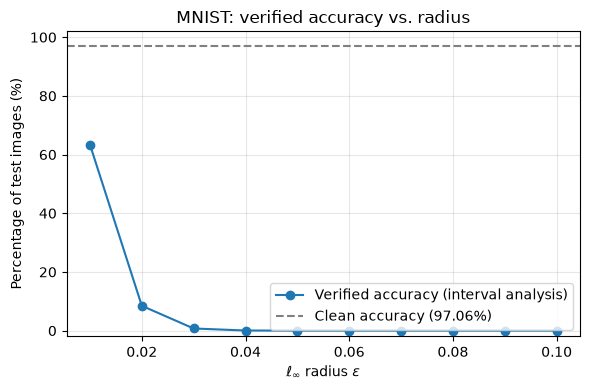

In [7]:
plt.figure(figsize=(6, 4))
plt.plot(epsilons, verified_accs, marker='o', label='Verified accuracy (interval analysis)')
plt.axhline(clean_acc, color='gray', linestyle='--', label=f'Clean accuracy ({clean_acc:.2f}%)')
plt.xlabel(r'$\ell_\infty$ radius $\epsilon$')
plt.ylabel('Percentage of test images (%)')
plt.title('MNIST: verified accuracy vs. radius')
plt.ylim(-2, 102)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('verified_accuracy.png', dpi=200)
plt.show()